In [ ]:
import pandas as pd

# 1. Memuat dataset
df = pd.read_csv('/content/penjualan_nusantaramart - penjualan_nusantaramart.csv')
print("===================================================")

# 2. Eksplorasi awal & statistika deskriptif
print(df.head())      # Menampilkan 5 baris pertama
print(df.info())      # Menampilkan tipe data & jumlah data non-null
print(df.describe())  # Menampilkan ringkasan statistik (mean, std, min, max, median)
print("===================================================")

# 3. Menghitung rata-rata total nilai transaksi per kategori produk
rata_kategori = df.groupby('kategori_produk')['total'].mean()
print(rata_kategori.sort_values(ascending=False))
print("===================================================")

# 4. Menghitung mean dan median kolom total secara keseluruhan
mean_total = df['total'].mean()
median_total = df['total'].median()

print(f"Mean Total  : {mean_total:.2f}")
print(f"Median Total: {median_total:.2f}")

   order_id     tanggal    kategori_produk        nama_produk   wilayah  \
0      1146  2026-01-03           Olahraga        Matras Yoga    Malang   
1      1166  2026-01-05            Fashion       Celana Jeans  Surabaya   
2      1190  2026-01-05          Kesehatan   Masker Medis Box  Semarang   
3      1219  2026-01-08  Makanan & Minuman  Kopi Kemasan 200g   Bandung   
4      1133  2026-01-10            Fashion         Tas Ransel  Surabaya   

   jumlah  harga_satuan   total metode_pembayaran  rating_pelanggan  
0       5         90000  450000          E-Wallet                 4  
1       5        175000  875000     Transfer Bank                 5  
2       4         30000  120000      Kartu Kredit                 3  
3       4         28000  112000          E-Wallet                 3  
4       4        130000  520000      Kartu Kredit                 4  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 220 entries, 0 to 219
Data columns (total 10 columns):
 #   Column             

• Kategori produk apa yang memiliki rata-rata nilai transaksi (total) tertinggi?

Kategori Elektronik memiliki rata-rata transaksi terbesar yaitu Rp363.541,67, diikuti oleh kategori Fashion di posisi kedua dengan Rp353.900,00.

• Apakah ada kolom yang memiliki data kosong (missing value)? Bagaimana cara
mengeceknya dari output df.info()?

Tidak ada data yang hilang ( missing value ) karena output df.info() mencatat seluruh 10 kolom memiliki 220 baris terisi penuh (220 non-null).

• Bandingkan nilai mean dan median kolom total secara keseluruhan. Apa yang bisa kamu
simpulkan tentang sebaran datanya?

Nilai rata-rata (Rp238.486,36) lebih besar dari nilai tengah/median (Rp125.000,00). Ini menandakan sebaran data miring ke kanan (positively skewed) karena terdorong oleh beberapa transaksi bernilai sangat tinggi.

/tmp/ipykernel_3759/61175289.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=total_kategori.values, y=total_kategori.index, palette='Blues_r')


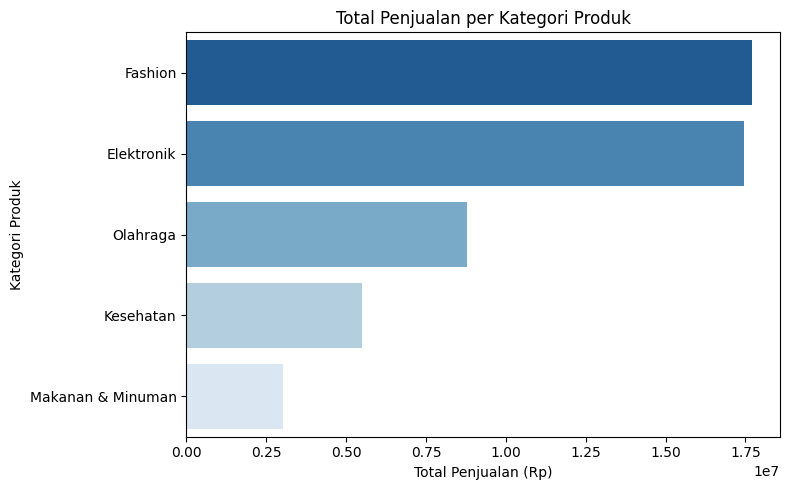

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Memuat dataset
df = pd.read_csv('/content/penjualan_nusantaramart - penjualan_nusantaramart.csv')

# Menghitung total penjualan per kategori produk
total_kategori = df.groupby('kategori_produk')['total'].sum().sort_values(ascending=False)

# Membuat visualisasi Bar Chart
plt.figure(figsize=(8, 5))
sns.barplot(x=total_kategori.values, y=total_kategori.index, palette='Blues_r')
plt.title('Total Penjualan per Kategori Produk')
plt.xlabel('Total Penjualan (Rp)')
plt.ylabel('Kategori Produk')
plt.tight_layout()
plt.show()

• Kategori apa yang menyumbang penjualan tertinggi dan terendah?

Penjualan Tertinggi dan Terendah: Kategori Fashion menyumbang total penjualan tertinggi sebesar Rp17.695.000, sedangkan Makanan & Minuman menjadi yang terendah dengan Rp3.029.000.

• Menurutmu, apa rekomendasi bisnis yang bisa diberikan kepada manajer Nusantara Mart
berdasarkan grafik ini?

Manajemen Nusantara Mart disarankan untuk menjaga ketersediaan stok dan meningkatkan promosi pada kategori Fashion dan Elektronik sebagai penyumbang pendapatan terbesar. Sementara itu, untuk mendorong kategori Makanan & Minuman yang berkinerja terendah, perusahaan dapat menerapkan strategi bundling produk serta mengevaluasi ulang variasi produk yang ditawarkan agar lebih sesuai dengan minat konsumen.

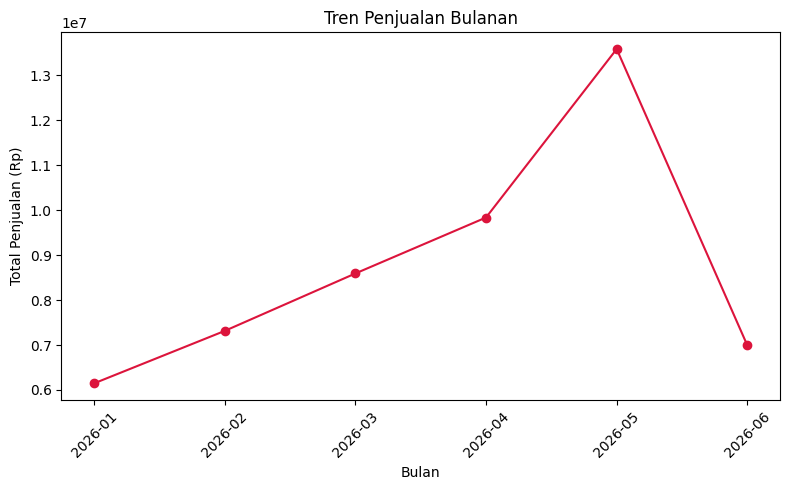

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Konversi kolom tanggal ke format datetime
df['tanggal'] = pd.to_datetime(df['tanggal'])

# 2. Ekstrak periode bulan
df['bulan'] = df['tanggal'].dt.to_period('M')

# 3. Hitung total penjualan per bulan
tren_bulanan = df.groupby('bulan')['total'].sum()

# 4. Visualisasi Tren Penjualan dengan Line Chart
plt.figure(figsize=(8, 5))
plt.plot(
    tren_bulanan.index.astype(str),
    tren_bulanan.values,
    marker='o',
    color='crimson',
)
plt.title('Tren Penjualan Bulanan')
plt.xlabel('Bulan')
plt.ylabel('Total Penjualan (Rp)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

• Bulan apa yang memiliki penjualan tertinggi? Menurutmu, apa kemungkinan penyebabnya?

Bulan Mei 2026 meraih total penjualan tertinggi sebesar Rp13.585.000. Kemungkinan penyebab utamanya adalah adanya momentum kampanye promo besar (seperti gajian/mid-year sale) atau peningkatan permintaan musiman di bulan tersebut.

• Apakah tren penjualan cenderung naik, turun, atau fluktuatif? Jelaskan.

Tren bersifat fluktuatif dengan tren naik di awal lalu melonjak dan turun kembali. Penjualan konsisten meningkat dari Januari hingga Mei (Rp6,14 juta ke Rp13,58 juta), namun mengalami penurunan signifikan pada bulan Juni kembali ke angka Rp6,99 juta



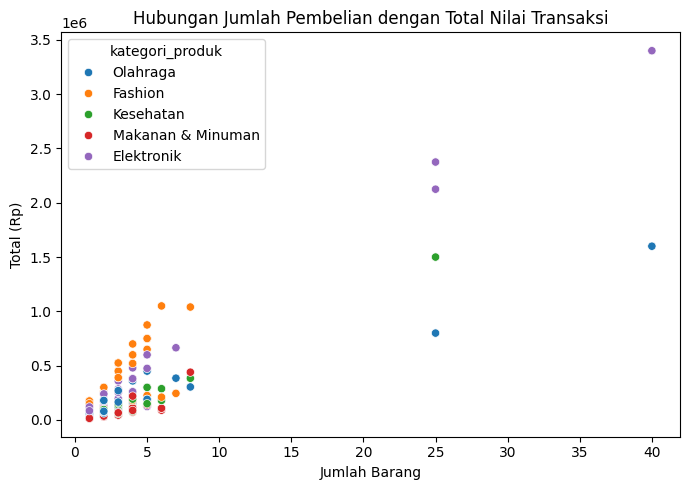

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Memuat dataset
df = pd.read_csv('penjualan_nusantaramart - penjualan_nusantaramart.csv')

# Membuat visualisasi Scatter Plot
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='jumlah', y='total', hue='kategori_produk')
plt.title('Hubungan Jumlah Pembelian dengan Total Nilai Transaksi')
plt.xlabel('Jumlah Barang')
plt.ylabel('Total (Rp)')
plt.tight_layout()
plt.show()

• Apakah terlihat pola hubungan antara jumlah barang dan total nilai transaksi? Jelaskan
hubungan tersebut (positif/negatif/tidak berhubungan).

Terlihat hubungan positif, yang berarti makin banyak jumlah barang yang dibeli konsumen, makin tinggi pula total nilai transaksinya.

• Apakah ada titik data yang terlihat jauh dari pola umum (kemungkinan outlier)? Sebutkan
kategorinya jika terlihat dari warna.

Terdapat beberapa titik data yang terpisah jauh dari kelompok mayoritas (jumlah barang 25 hingga 40 unit dengan nilai total melampaui Rp1,5 juta hingga Rp3,4 juta). Kategori yang paling menonjol sebagai outlier adalah Elektronik, diikuti oleh Olahraga dan Kesehatan

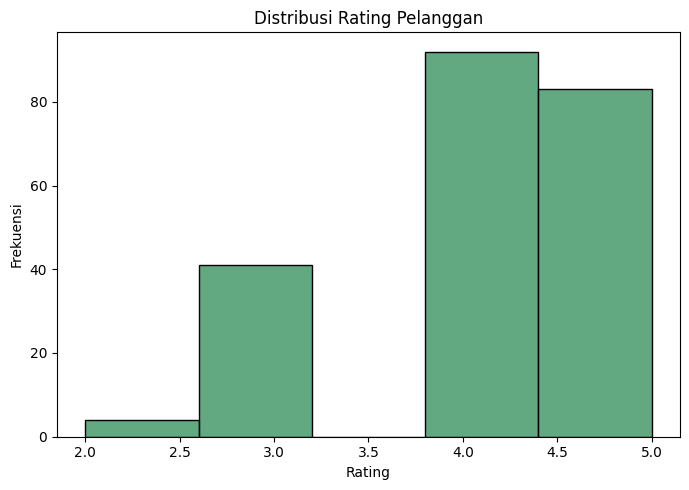

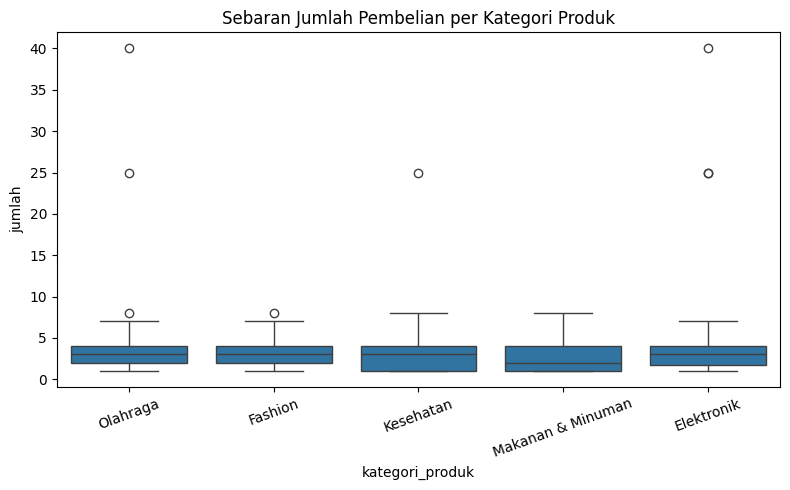

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Histogram distribusi rating pelanggan
plt.figure(figsize=(7, 5))
sns.histplot(df['rating_pelanggan'], bins=5, color='seagreen')
plt.title('Distribusi Rating Pelanggan')
plt.xlabel('Rating')
plt.ylabel('Frekuensi')
plt.tight_layout()
plt.show()

# 2. Boxplot jumlah pembelian per kategori
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='kategori_produk', y='jumlah')
plt.title('Sebaran Jumlah Pembelian per Kategori Produk')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

• Bagaimana bentuk distribusi rating pelanggan? Apakah cenderung tinggi, rendah, atau
merata?

Distribusi rating cenderung tinggi (negatively skewed). Sebagian besar pelanggan memberikan penilaian yang sangat baik, di mana rating 4 (92 transaksi) dan rating 5 (83 transaksi) mendominasi, sementara rating rendah seperti 2 sangat minim (hanya 4 transaksi).

• Kategori produk mana yang memiliki titik-titik di luar kotak boxplot (outlier)? Apa
kemungkinan penyebabnya (misalnya pembelian oleh reseller)?

Kategori Olahraga, Elektronik, dan Kesehatan memiliki titik pencilan (outlier) ekstrem di luar kotak boxplot (mencapai 25 hingga 40 unit per transaksi). Kemungkinan besar hal ini disebabkan oleh transaksi grosir oleh pembeli reseller, pengadaan barang instansi/kantor, atau pembelian stok musiman

/tmp/ipykernel_3759/2446741439.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


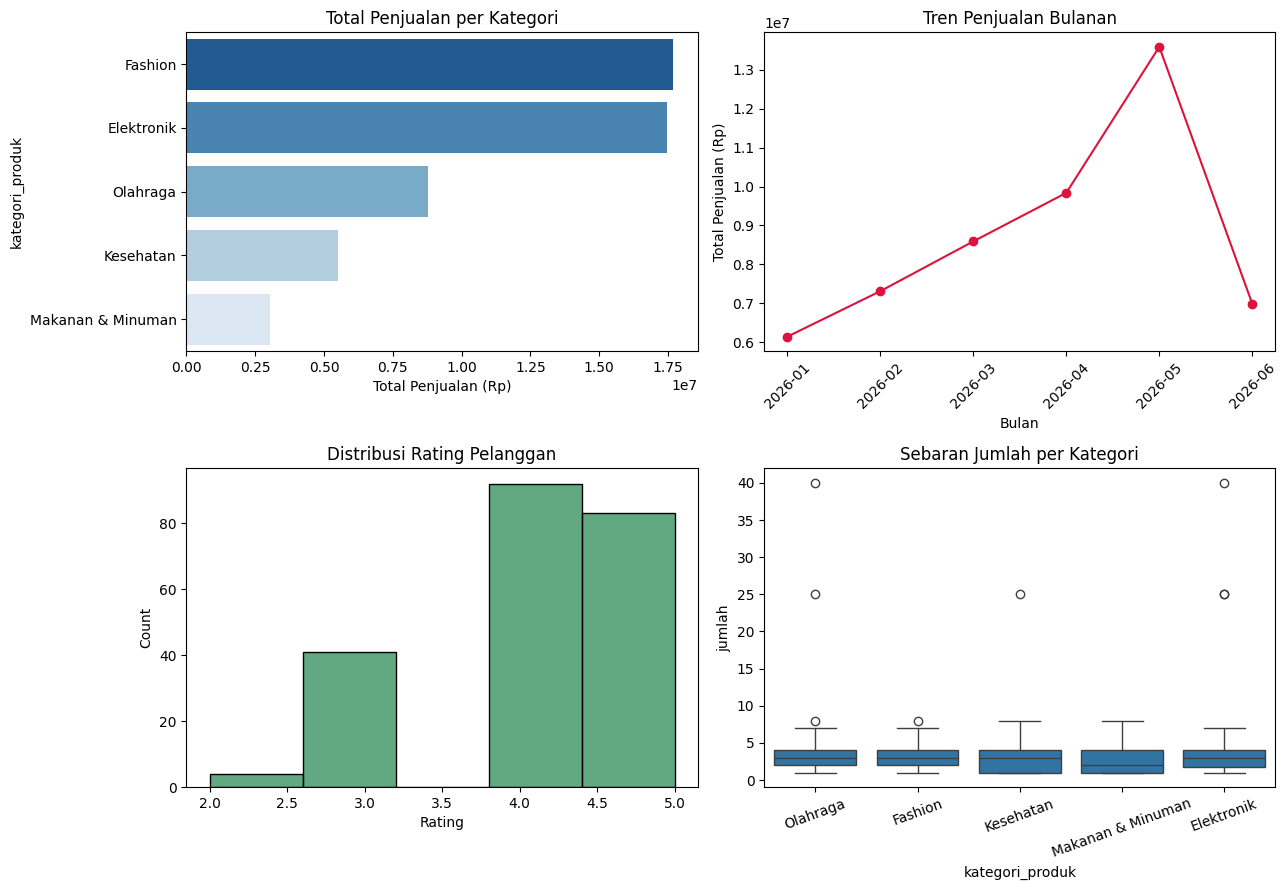

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Memuat dan menyiapkan data
df = pd.read_csv('penjualan_nusantaramart - penjualan_nusantaramart.csv')
df['tanggal'] = pd.to_datetime(df['tanggal'])
df['bulan'] = df['tanggal'].dt.to_period('M')

total_kategori = (
    df.groupby('kategori_produk')['total'].sum().sort_values(ascending=False)
)
tren_bulanan = df.groupby('bulan')['total'].sum()

# Membuat Dashboard 2x2
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Chart 1: Total Penjualan per Kategori
sns.barplot(
    x=total_kategori.values,
    y=total_kategori.index,
    ax=axes[0, 0],
    palette='Blues_r',
)
axes[0, 0].set_title('Total Penjualan per Kategori')
axes[0, 0].set_xlabel('Total Penjualan (Rp)')

# Chart 2: Tren Penjualan Bulanan
axes[0, 1].plot(
    tren_bulanan.index.astype(str),
    tren_bulanan.values,
    marker='o',
    color='crimson',
)
axes[0, 1].set_title('Tren Penjualan Bulanan')
axes[0, 1].set_xlabel('Bulan')
axes[0, 1].set_ylabel('Total Penjualan (Rp)')
axes[0, 1].tick_params(axis='x', rotation=45)

# Chart 3: Distribusi Rating Pelanggan
sns.histplot(df['rating_pelanggan'], bins=5, ax=axes[1, 0], color='seagreen')
axes[1, 0].set_title('Distribusi Rating Pelanggan')
axes[1, 0].set_xlabel('Rating')

# Chart 4: Sebaran Jumlah Pembelian per Kategori
sns.boxplot(data=df, x='kategori_produk', y='jumlah', ax=axes[1, 1])
axes[1, 1].set_title('Sebaran Jumlah per Kategori')
axes[1, 1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

• Menurutmu, apa keuntungan menyajikan beberapa grafik dalam satu dashboard
dibandingkan grafik terpisah-pisah?

Menyajikan beberapa grafik dalam satu tampilan memudahkan manajemen untuk melihat gambaran menyeluruh (holistic view) secara cepat. Hal ini mempercepat pembandingan antarmetrik, seperti menghubungkan kinerja kategori produk, tren bulanan, tingkat kepuasan pelanggan, dan volume pembelian tanpa harus berpindah-pindah dokumen

• Jika kamu adalah manajer Nusantara Mart, keputusan bisnis apa yang akan kamu ambil
setelah melihat dashboard ini?

Memfokuskan pasokan pada kategori utama (Fashion & Elektronik) serta menyediakan layanan khusus pembelian grosir untuk mengakomodasi pesanan volume besar pada kategori Elektronik dan Olahraga
